# Grammar scoring from spoken audio (SHL hiring assessment 2026)

Kaggle username: `shashwatfr`

I predict a grammar score from 0 to 5 for each short spoken clip. The metric is RMSE, so lower is better.

## Summary of the approach

I never train a speech model. The pipeline has three parts:

1. **Frozen encoders as feature extractors.** Each clip goes through pretrained models (Whisper small and Whisper medium). For every hidden layer I take the mean and standard deviation of the frame vectors over time. That gives one fixed-length vector per clip per layer.
2. **A text side channel.** Whisper small transcribes the clip. From the transcript I compute simple fluency statistics (length, repetition, compression ratio, sentence length) and GPT-2 token negative log-likelihood (a rough fluency / grammaticality signal).
3. **Ridge regression per feature group, then a fixed weighted blend.** Each group gets its own StandardScaler + Ridge. The three out-of-fold predictions are blended with fixed weights 5 : 2 : 1 (medium, small, text) and clipped to [0, 5].

There are only 769 labelled clips, so I kept the models small and linear. I tried heavier things (an attention-pooling head, SVR, Whisper large-v3, BGE text embeddings, sample weighting, an NNLS blend). None of them beat the plain ridge blend in cross-validation, so they are not in this notebook.

I also tried WavLM base plus as a third encoder. Adding it moved CV RMSE from 0.521 to 0.513 and made no meaningful difference on the test-like subset (about 0.545 either way). On the public leaderboard the version with WavLM scored 0.3956 and the final version without it scores 0.4018. Its model card points to a CC BY-SA licence, which is not OSI-approved, so I left it out of the final pipeline.

## Data issues that shaped the setup

* **Train and test share file names.** 212 names appear in both folders, but the audio is different (checked by hash). Everything is therefore keyed by full path, never by basename.
* **37 clips have a label of 0** (ids 5037 to 5073). They are a separate, louder recording batch and look nothing like the rest. I leave them out of training and out of the headline metrics, and I report the effect of including them below.
* **There is a distribution shift between train and test.** A classifier separating train from test audio gets an AUC of about 0.85. The first 216 train clips (ids 0 to 215, "batch A") look most like the test set, so I report metrics on that subset as well as on all non-zero rows.
* **`sample_submission.csv` is stale** (204 rows). The test set has 216 rows, so the submission is keyed by `test.csv`.

In [5]:
%pip install -q kagglehub soundfile transformers accelerate

In [6]:
import os, re, json, zlib, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

CACHE = "cache"        # extracted features live here so I only pay for the GPU once
os.makedirs(CACHE, exist_ok=True)
os.makedirs("figs", exist_ok=True)

SEED = 0

## 1. Getting the data

In Colab the Kaggle token sits in a secret called `KAGGLE_KEY`. The new-style tokens start with `KGAT_` and have to go in `KAGGLE_API_TOKEN`; the old `KAGGLE_USERNAME` / `KAGGLE_KEY` pair gives a 401. I clear those two first so the old pair can't override it. Outside Colab, set `KAGGLE_API_TOKEN` yourself, or set `SHL_ROOT` to an already-downloaded copy.

In [8]:
root = os.environ.get("SHL_ROOT")
if root is None:
    try:
        from google.colab import userdata
        for k in ("KAGGLE_USERNAME", "KAGGLE_KEY"):
            os.environ.pop(k, None)
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_KEY").strip()
    except ImportError:
        assert "KAGGLE_API_TOKEN" in os.environ, "set KAGGLE_API_TOKEN or SHL_ROOT"
    import kagglehub
    root = kagglehub.competition_download("shl-hiring-assessment-2026")
print("data root:", root)

def find(name):
    hits = glob.glob(f"{root}/**/{name}", recursive=True)
    assert hits, f"{name} not found under {root}"
    return hits[0]

train = pd.read_csv(find("train.csv"))
test = pd.read_csv(find("test.csv"))
assert "label" in train.columns, train.columns

audio_root = f"{root}/Dataset_Final"
assert os.path.isdir(audio_root), os.listdir(root)
train["path"] = f"{audio_root}/train/" + train.filename
test["path"] = f"{audio_root}/test/" + test.filename
train["id"] = train.filename.str.extract(r"(\d+)")[0].astype(int)

print(train.shape, test.shape)
print(train.label.value_counts().sort_index())

data root: /root/.cache/kagglehub/competitions/shl-hiring-assessment-2026
(769, 4) (216, 3)
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


## 2. Feature extraction

Every extractor is cached to `cache/`. If the `.npy` file is already there the extractor is skipped. All audio is 16 kHz mono.

* **Whisper encoder (small, medium)**: Whisper only accepts 30 s windows, so a clip is cut into 30 s chunks. The padded frames are dropped (the encoder runs at 50 frames per second) and the mean and std are accumulated across chunks. Small gives 13 x 1536 and medium gives 25 x 2048 per clip (layers x mean+std).
* **Transcripts**: Whisper small via the ASR pipeline. Whisper sometimes gets stuck in a loop and repeats a phrase dozens of times on unclear audio, so repeated n-grams are trimmed before I compute any text statistics.

In [9]:
def read_wav(p):
    import soundfile as sf
    wav, sr = sf.read(p, dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(1)
    assert sr == 16000, (p, sr)
    return wav


def extract_whisper(paths, name):
    import torch
    from tqdm.auto import tqdm
    from transformers import WhisperFeatureExtractor, WhisperModel
    fe = WhisperFeatureExtractor.from_pretrained(name)
    enc = WhisperModel.from_pretrained(name, torch_dtype=torch.float16).encoder.cuda().eval()
    win = 30 * 16000
    out = []
    for p in tqdm(list(paths)):
        wav = read_wav(p)
        s1 = s2 = 0.0
        count = 0
        for i in range(0, len(wav), win):
            c = wav[i:i + win]
            if len(c) < 1600 and i > 0:      # skip a sliver of a last chunk
                continue
            feats = fe(c, sampling_rate=16000, return_tensors="pt").input_features
            with torch.no_grad():
                hs = enc(feats.half().cuda(), output_hidden_states=True).hidden_states
            valid = max(int(np.ceil(len(c) / 320)), 1)         # 50 frames/s, drop the padding
            h = torch.stack(hs)[:, 0, :valid].float()           # (L, valid, D)
            s1 = s1 + h.sum(1)
            s2 = s2 + (h ** 2).sum(1)
            count += valid
        mean = s1 / count
        std = (s2 / count - mean ** 2).clamp(min=0).sqrt()
        out.append(torch.cat([mean, std], -1).cpu().numpy())
    return np.stack(out)


def feature_pair(tag, fn, dtype=np.float32):
    ftr, fte = f"{CACHE}/{tag}_train.npy", f"{CACHE}/{tag}_test.npy"
    if not (os.path.exists(ftr) and os.path.exists(fte)):
        np.save(ftr, fn(train.path).astype(dtype))
        np.save(fte, fn(test.path).astype(dtype))
    return np.load(ftr), np.load(fte)


Ws_tr, Ws_te = feature_pair("whisper", lambda p: extract_whisper(p, "openai/whisper-small"))
Wm_tr, Wm_te = feature_pair("whisperM", lambda p: extract_whisper(p, "openai/whisper-medium"), np.float16)
print(Ws_tr.shape, Wm_tr.shape)

(769, 13, 1536) (769, 25, 2048)


In [10]:
def transcribe(paths, out_file):
    import torch
    from tqdm.auto import tqdm
    from transformers import pipeline
    done = json.load(open(out_file)) if os.path.exists(out_file) else {}
    todo = [p for p in paths if p not in done]
    if todo:
        asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
                       device=0, torch_dtype=torch.float16, chunk_length_s=30)
        for i in tqdm(range(0, len(todo), 16)):
            batch = todo[i:i + 16]
            res = asr([{"raw": read_wav(p), "sampling_rate": 16000} for p in batch],
                      batch_size=16, generate_kwargs={"language": "en", "task": "transcribe"})
            for p, r in zip(batch, res):
                done[p] = r["text"].strip()
            json.dump(done, open(out_file, "w"))      # save every batch, Colab dies on me sometimes
    return done


def trim_loops(text, max_period=8, max_rep=3):
    # collapse a phrase (1 to max_period words) repeated back to back more than max_rep times
    w = text.split()
    out, i = [], 0
    while i < len(w):
        for p in range(1, max_period + 1):
            g = w[i:i + p]
            k = 1
            while len(g) == p and w[i + k * p:i + (k + 1) * p] == g:
                k += 1
            if k > max_rep:
                out += g * max_rep
                i += k * p
                break
        else:
            out.append(w[i])
            i += 1
    return " ".join(out)


def hand(t):
    w = t.lower().split()
    if not w:
        return [0.0] * 6
    nw = len(w)
    raw = t.encode()
    bigrams = list(zip(w, w[1:]))
    sents = [s for s in re.split(r"[.!?]+", t) if s.strip()]
    return [
        np.log1p(nw),                                          # log_words
        len(set(w)) / nw,                                      # unique_ratio
        len(zlib.compress(raw)) / max(len(raw), 1),            # compress_ratio
        1 - len(set(bigrams)) / len(bigrams) if bigrams else 0.0,   # repeat_bigram
        nw / max(len(sents), 1),                               # sent_len
        float(np.mean([len(x) for x in w])),                   # word_len
    ]


def gpt2_feats(texts):
    import torch
    import torch.nn.functional as F
    from tqdm.auto import tqdm
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained("gpt2")
    lm = AutoModelForCausalLM.from_pretrained("gpt2").cuda().eval()
    out = []
    for t in tqdm(texts):
        ids = tok(t, return_tensors="pt", truncation=True, max_length=1024).input_ids
        if ids.shape[1] < 3:
            out.append([0.0, 0.0, 0.0])
            continue
        ids = ids.cuda()
        with torch.no_grad():
            logits = lm(ids).logits[0, :-1]
        nll = F.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
        out.append([nll.mean(), nll.std(), np.percentile(nll, 90)])
    return np.array(out)


def text_features(paths, transcripts):
    texts = [trim_loops(transcripts[p]) for p in paths]
    return np.c_[np.array([hand(t) for t in texts]), gpt2_feats(texts)]


tf_file = f"{CACHE}/text_feats.npz"
if os.path.exists(tf_file):
    z = np.load(tf_file)
    T_tr, T_te = z["tr"], z["te"]
else:
    tr_all = transcribe(list(train.path) + list(test.path), f"{CACHE}/transcripts.json")
    T_tr, T_te = text_features(train.path, tr_all), text_features(test.path, tr_all)
    np.savez(tf_file, tr=T_tr, te=T_te)
print(T_tr.shape, T_te.shape)

(769, 9) (216, 9)


## 3. Feature groups, validation and models

Which layers and which alpha for each group came out of the layer sweeps and alpha grids I ran earlier, using the same CV as below:

| group | features | ridge alpha |
|---|---|---|
| Whisper medium | last encoder layer (24), mean+std | 1000 |
| Whisper small | layers 9 to 12 concatenated | 3000 |
| text | 9 transcript statistics | 10 |

**Validation.** 5-fold stratified CV (stratified on the rounded score, seed 0). Zero-label rows are never used for fitting, but they do get out-of-fold predictions so I can show what happens if they are scored. The headline numbers are on non-zero rows. I also report batch A (ids 0 to 215), the part of train that looks most like the test set.

In [11]:
y = train.label.values.astype(float)
n = len(train)
nz = y > 0                                   # the 37 zero-label clips are a different recording batch
A = (train.id.values <= 215) & nz            # test-like subset
strat = np.round(y).astype(int).clip(1, 5)
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(n), strat))

# feature groups: name -> (train matrix, test matrix, ridge alpha)
G = {
    "whisper-medium L24": (Wm_tr[:, 24].astype(np.float32), Wm_te[:, 24].astype(np.float32), 1000),
    "whisper-small L9-12": (Ws_tr[:, 9:13].reshape(n, -1), Ws_te[:, 9:13].reshape(len(test), -1), 3000),
    "text": (T_tr, T_te, 10),
}
names = list(G)
W_FULL = np.array([5.0, 2.0, 1.0])           # same order as names; blend() normalises


def make_model(alpha):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def cv_oof(X, alpha):
    oof = np.zeros(n)
    for tr, va in folds:
        tr = tr[nz[tr]]
        oof[va] = make_model(alpha).fit(X[tr], y[tr]).predict(X[va])
    return oof.clip(0, 5)


def blend(P, w):
    return (P @ (np.asarray(w) / np.sum(w))).clip(0, 5)


def summarize(pred):
    return dict(rmse=rmse(pred[nz], y[nz]), r=np.corrcoef(pred[nz], y[nz])[0, 1],
                rmse_A=rmse(pred[A], y[A]), r_A=np.corrcoef(pred[A], y[A])[0, 1])


oof = {k: cv_oof(X, a) for k, (X, _, a) in G.items()}
P_oof = np.c_[[oof[k] for k in names]].T
oof_blend = blend(P_oof, W_FULL)

## 4. Results

`in-sample` is the compulsory training-data RMSE: the model is fit on all non-zero training rows and scored on those same rows, so it is optimistic. `CV` columns are out-of-fold and are the honest estimate. The first row is a constant prediction (the mean label) for scale.

In [12]:
rows_all = np.where(nz)[0]
fitted = {k: make_model(a).fit(X[rows_all], y[rows_all]) for k, (X, _, a) in G.items()}
P_in = np.c_[[fitted[k].predict(G[k][0]) for k in names]].T.clip(0, 5)
in_blend = blend(P_in, W_FULL)

const = np.full(n, y[nz].mean())
rows = [{"model": "constant (mean label)", "in-sample RMSE": rmse(const[nz], y[nz]), **summarize(const)}]
for i, k in enumerate(names):
    rows.append({"model": k, "in-sample RMSE": rmse(P_in[nz, i], y[nz]), **summarize(oof[k])})
rows.append({"model": "BLEND (5:2:1)", "in-sample RMSE": rmse(in_blend[nz], y[nz]), **summarize(oof_blend)})

res = pd.DataFrame(rows).rename(columns={"rmse": "CV RMSE", "r": "CV r", "rmse_A": "CV RMSE (batch A)", "r_A": "CV r (batch A)"})
res = res.set_index("model").round(3)
display(res)

print("Training-data RMSE of the final blend (non-zero rows):", round(rmse(in_blend[nz], y[nz]), 4))
print("Same, if the 37 zero-label clips are scored too:      ", round(rmse(in_blend, y), 4),
      "(the model never saw them and predicts them like normal clips)")
print("Out-of-fold RMSE of the final blend (non-zero rows):  ", round(rmse(oof_blend[nz], y[nz]), 4))

,in-sample RMSE,CV RMSE,CV r,CV RMSE (batch A),CV r (batch A)
model,,,,,
constant (mean label),1.014,1.014,-0.000,0.976,0.000
whisper-medium L24,0.317,0.525,0.856,0.548,0.802
whisper-small L9-12,0.363,0.548,0.841,0.586,0.770
text,0.749,0.759,0.663,0.744,0.648
BLEND (5:2:1),0.349,0.521,0.863,0.545,0.809


Training-data RMSE of the final blend (non-zero rows): 0.349
Same, if the 37 zero-label clips are scored too:       0.6522 (the model never saw them and predicts them like normal clips)
Out-of-fold RMSE of the final blend (non-zero rows):   0.5208


### Ablation: what does each part buy?

Each row drops one group and renormalises the remaining weights. Same folds as above.

In [13]:
abl = {}
abl["all three (final)"] = oof_blend
for i, k in enumerate(names):
    w = W_FULL.copy()
    w[i] = 0
    abl["without " + k] = blend(P_oof, w)
tab = pd.DataFrame({k: summarize(v) for k, v in abl.items()}).T
tab.columns = ["CV RMSE", "CV r", "CV RMSE (batch A)", "CV r (batch A)"]
display(tab.round(3))

,CV RMSE,CV r,CV RMSE (batch A),CV r (batch A)
all three (final),0.521,0.863,0.545,0.809
without whisper-medium L24,0.557,0.846,0.583,0.788
without whisper-small L9-12,0.523,0.862,0.543,0.811
without text,0.523,0.858,0.548,0.801


## 5. Visualisations

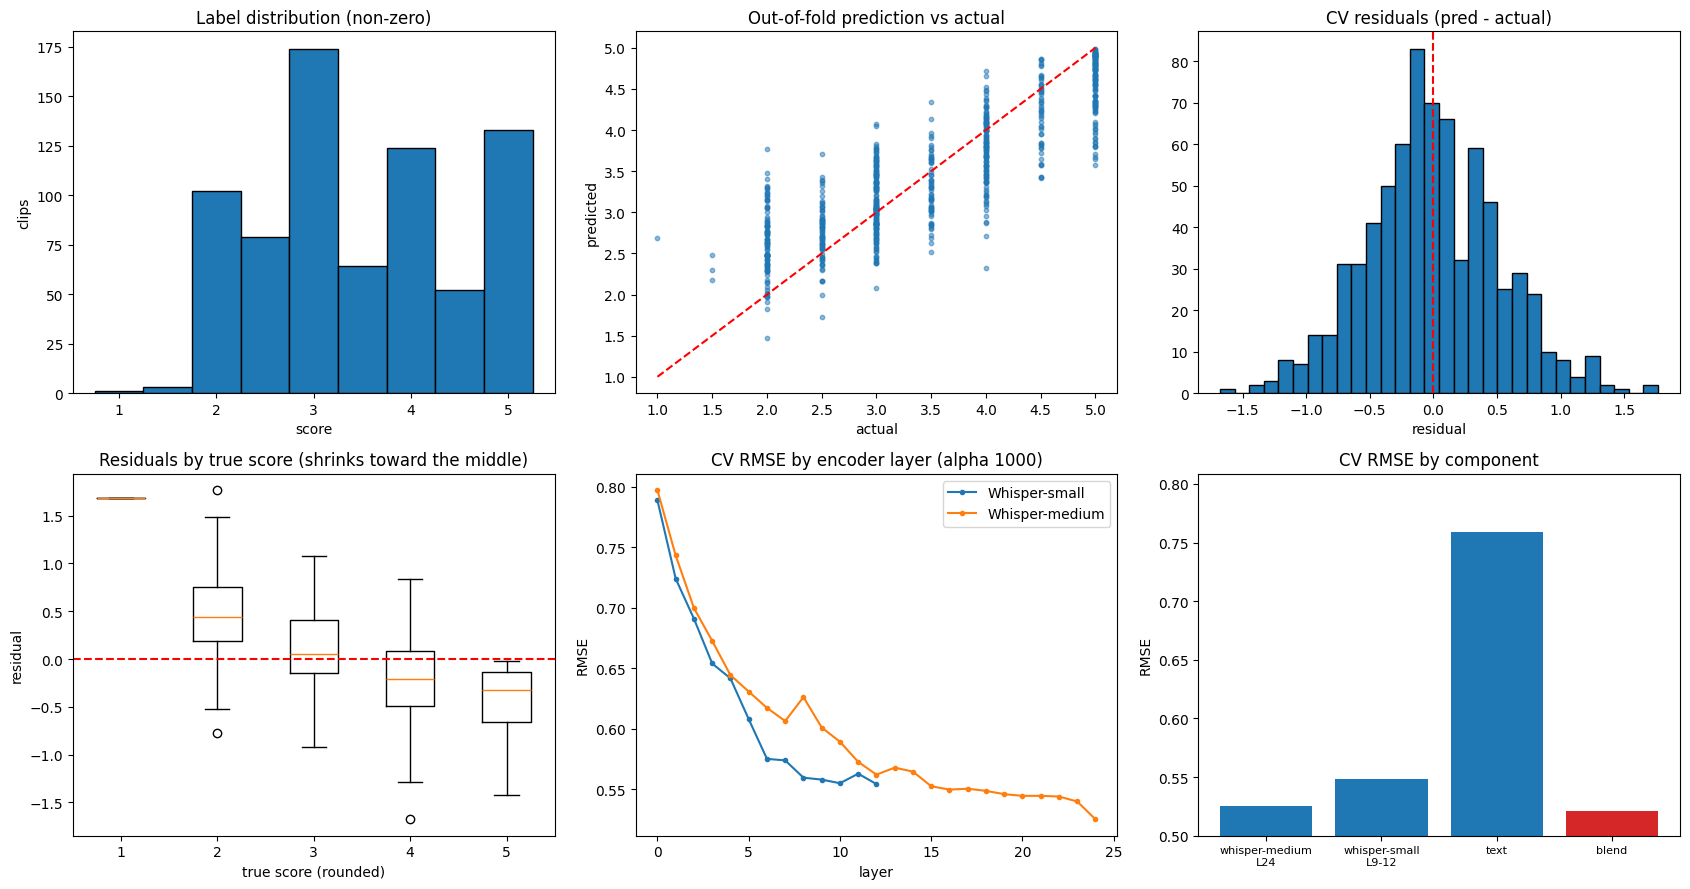

In [14]:
def layer_sweep(arr, alpha=1000):
    return [rmse(cv_oof(arr[:, l].astype(np.float32), alpha)[nz], y[nz]) for l in range(arr.shape[1])]

sweeps = {"Whisper-small": layer_sweep(Ws_tr), "Whisper-medium": layer_sweep(Wm_tr)}

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
resid = oof_blend - y

ax[0, 0].hist(y[nz], bins=np.arange(0.75, 5.5, 0.5), edgecolor="k")
ax[0, 0].set(title="Label distribution (non-zero)", xlabel="score", ylabel="clips")

ax[0, 1].scatter(y[nz], oof_blend[nz], s=10, alpha=0.5)
ax[0, 1].plot([1, 5], [1, 5], "r--")
ax[0, 1].set(title="Out-of-fold prediction vs actual", xlabel="actual", ylabel="predicted")

ax[0, 2].hist(resid[nz], bins=30, edgecolor="k")
ax[0, 2].axvline(0, color="r", ls="--")
ax[0, 2].set(title="CV residuals (pred - actual)", xlabel="residual")

groups = [resid[nz & (np.round(y) == s)] for s in range(1, 6)]
ax[1, 0].boxplot(groups)
ax[1, 0].set_xticklabels([1, 2, 3, 4, 5])
ax[1, 0].axhline(0, color="r", ls="--")
ax[1, 0].set(title="Residuals by true score (shrinks toward the middle)", xlabel="true score (rounded)", ylabel="residual")

for k, v in sweeps.items():
    ax[1, 1].plot(v, marker="o", ms=3, label=k)
ax[1, 1].set(title="CV RMSE by encoder layer (alpha 1000)", xlabel="layer", ylabel="RMSE")
ax[1, 1].legend()

comp_rmse = [rmse(oof[k][nz], y[nz]) for k in names] + [rmse(oof_blend[nz], y[nz])]
ax[1, 2].bar(range(4), comp_rmse, color=["C0"] * 3 + ["C3"])
ax[1, 2].set_xticks(range(4))
ax[1, 2].set_xticklabels([k.replace(" ", "\n") for k in names] + ["blend"], fontsize=8)
ax[1, 2].set(title="CV RMSE by component", ylabel="RMSE", ylim=(0.5, max(comp_rmse) + 0.05))

plt.tight_layout()
plt.savefig("figs/results.png", dpi=130)
plt.show()

### Reading the results

* The best single piece is the Whisper-medium last encoder layer. The blend improves on it only a little, because the groups are highly correlated.
* Predictions shrink toward the middle: low scores are over-predicted and high scores under-predicted. That is what a regularised linear model does when the signal is weak, and it is why I clip to [0, 5] instead of trying to stretch the predictions.
* My CV is about 0.52 to 0.55 RMSE, but the public leaderboard score of the submitted file is lower (0.4018). I think that is down to the test clips being easier or more homogeneous than my train folds (the adversarial AUC says they are different), not to the model being better than CV says. I wouldn't read anything into the gap beyond that.
* The hyperparameters (layers, alphas, blend weights) were picked on the same CV folds, so the CV numbers are slightly optimistic. The in-sample RMSE is lower still and shouldn't be used as a quality estimate.
* In the ablation, dropping Whisper medium costs about 0.036 RMSE, so it carries the model. Dropping Whisper small or the text group costs only about 0.002, which is inside fold noise on 769 clips. They stay in because they don't hurt and the blend was fixed before I looked at this table, but I wouldn't claim they each add something.

## 6. Final fit and submission

Each group is refit on all non-zero training rows (done above in `fitted`), predicted on the test set, blended and clipped. The file is keyed by `test.csv` because `sample_submission.csv` has the wrong number of rows.

In [15]:
P_te = np.c_[[fitted[k].predict(G[k][1]) for k in names]].T.clip(0, 5)
pred = blend(P_te, W_FULL)

sub = pd.DataFrame({"filename": test.filename, "label": pred})
assert len(sub) == len(test) == sub.filename.nunique()
assert sub.label.notna().all() and sub.label.between(0, 5).all()
sub.to_csv("submission.csv", index=False)
print(sub.shape, "| mean %.2f std %.2f min %.2f max %.2f" % (pred.mean(), pred.std(), pred.min(), pred.max()))
sub.head()

(216, 2) | mean 3.33 std 0.78 min 1.64 max 4.95


,filename,label
0,audio_128.wav,3.266146
1,audio_156.wav,4.027437
2,audio_19.wav,4.419337
3,audio_108.wav,2.315959
4,audio_206.wav,2.399807


## 7. Limitations

* Only 769 labelled clips, and the label noise is probably large (the scores are subjective), so the achievable RMSE is bounded by that.
* Everything downstream of the encoders is linear. An attention-pooling head I tried over frame-level features did not do better (CV about 0.55).
* Transcripts come from Whisper, which tends to repair grammar mistakes while transcribing. That limits how much the text features can see.
* I did not do any calibration of the output scale, and I did not use timing features (pauses, speaking rate). Both are things I would try next.